# Second Thought: a Zoro-1 driver that learns when to stop and think

A toy self-driving car makes every move with **one Zoro-1 decision call** (the *reflex*): a `choice` over five
moves plus six yes/no checks, all answered from one prefill with calibrated probabilities. When the reflex is
unsure, or its pick fails a physics check, the car takes a **second look**: it simulates every move 4 seconds
ahead, throws out the ones that crash or break a rule, and asks Zoro-1 again with those futures in front of it.

Every second look is a free training label. After each round the notebook fits a tiny head (60 numbers) on
Zoro-1's own reflex answers, so the next round is unsure less often. No people label anything, no GPU training:
the loop runs in a second on the CPU.

**Run it:** start a Zoro-1 server ([Run Zoro-1](../README.md#run-zoro-1)) and run all cells. No server? Set
`MOCK = True` in the next cell (or `ZORO_MOCK=1` in the environment) and it runs with fake answers.

*The outputs below are from one run against the real Zoro-1 (SGLang decision server on a Colab T4 GPU,
`ZORO_CONCURRENCY=4`). Run it to get your own.*

In [1]:
# Setup. Dependencies: httpx, and matplotlib for the chart at the end (skipped if missing).
# %pip install -q httpx matplotlib
import os

ZORO_URL = os.environ.get("ZORO_URL", "http://127.0.0.1:8080")   # MLX server; SGLang: http://GPU_HOST:30001
MOCK = os.environ.get("ZORO_MOCK", "0") == "1"                   # True: no model needed
CONCURRENCY = int(os.environ.get("ZORO_CONCURRENCY", "1"))      # 1 for the Mac (MLX); 4-8 for SGLang, which batches

SEED = 7                 # scenes are random but reproducible
ROUNDS = 3               # drive, take second looks, retrain the head, repeat
SCENES_PER_ROUND = 30
TEST_SCENES = 40         # fresh scenes at the end: raw Zoro-1 reflex vs the learned head
TAU = 0.6                # a reflex with lower confidence than this takes a second look
AUDIT = 0.1              # this share of confident reflexes gets a second look anyway, so the head can't fool itself

## The road

A scene is a small JSON object, and it is exactly what Zoro-1 sees as `state`. The same object drives a tiny
physics model: `rollout(scene, move)` simulates 4 seconds and reports whether the move hits the car ahead, cuts
into the car next to us, runs a red light, rushes a crosswalk, or breaks the speed limit. Stable fields come first,
so the server's prefix cache can reuse them.

In [2]:
import math
import random

MOVES = {   # key: (description Zoro-1 sees, acceleration in m/s^2)
    "keep": ("hold the current speed", 0.0),
    "speed_up": ("speed up gently (+1.5 m/s2)", 1.5),
    "ease_off": ("slow down gently (-2 m/s2)", -2.0),
    "brake": ("brake hard (-6 m/s2)", -6.0),
    "change_left": ("change to the left lane", 0.0),
}
GENTLE = ["I'm feeling carsick, please drive smoothly.", "The baby just fell asleep in the back, easy does it."]
HURRY = ["I'm late for my flight, please hurry!", "The movie starts in five minutes, can we go faster?"]
CALM = ["Nice weather today.", "(the passenger is quiet)"]


def make_scene(rng):
    limit = rng.choice([30, 50, 60])
    speed = round(rng.uniform(0.5, 1.0) * limit)
    scene = {"road": "two-lane city street, you drive in the right lane", "speed_limit_kmh": limit,
             "your_speed_kmh": speed}
    lead = None
    if rng.random() < 0.7:
        lead = {"distance_m": round(rng.uniform(8, 70)), "speed_kmh": round(rng.uniform(0.0, 1.0) * limit),
                "brake_lights": "on" if rng.random() < 0.35 else "off"}
    kind = rng.choices(["clear", "light", "crosswalk"], [0.4, 0.3, 0.3])[0]
    if kind == "light":
        ahead = {"traffic_light": rng.choice(["green", "yellow", "red"]), "distance_m": round(rng.uniform(15, 70))}
    elif kind == "crosswalk":
        who = rng.choice(["a pedestrian is crossing", "a pedestrian is waiting at the curb"])
        ahead = {"crosswalk": who, "distance_m": round(rng.uniform(15, 60))}
    else:
        ahead = "clear road"
    if lead and isinstance(ahead, dict) and lead["distance_m"] < ahead["distance_m"] and must_stop_at(ahead):
        lead["brake_lights"] = "on"          # the car ahead stops for the same light / pedestrian
    scene["car_ahead"] = lead or "none"
    scene["left_lane"] = rng.choices(["free", "a car is right next to you", "there is no left lane"], [0.5, 0.3, 0.2])[0]
    scene["ahead"] = ahead
    scene["passenger_says"] = rng.choice(rng.choices([CALM, GENTLE, HURRY], [0.4, 0.3, 0.3])[0])
    return scene


def must_stop_at(ahead):
    return ahead.get("traffic_light") in ("red", "yellow") or ahead.get("crosswalk") == "a pedestrian is crossing"


def rollout(scene, move, horizon=4.0, dt=0.1):
    """Simulate `move` for `horizon` seconds -> what happens (safe?, why not, distance, end speed, ...)."""
    acc = MOVES[move][1]
    v, x = scene["your_speed_kmh"] / 3.6, 0.0
    lead = scene["car_ahead"] if isinstance(scene["car_ahead"], dict) else None
    lx, lv = (lead["distance_m"], lead["speed_kmh"] / 3.6) if lead else (None, None)
    ahead = scene["ahead"] if isinstance(scene["ahead"], dict) else None
    why, min_gap, t = None, math.inf, 0.0
    if move == "change_left" and scene["left_lane"] == "there is no left lane":
        why = "there is no left lane"
    for _ in range(round(horizon / dt)):
        t += dt
        prev_x = x
        v = max(0.0, v + acc * dt)
        x += v * dt
        if lead:
            if lead["brake_lights"] == "on":
                lv = max(0.0, lv - 4.0 * dt)
            lx += lv * dt
        in_left = move == "change_left" and t >= 1.5
        if lead and not in_left:
            min_gap = min(min_gap, lx - x)
            if lx - x < 2.0 and why is None:
                why = "hits the car ahead"
        if move == "change_left" and scene["left_lane"] == "a car is right next to you" and why is None:
            why = "cuts into the car next to you"
        if ahead and why is None and prev_x < ahead["distance_m"] <= x:
            light = ahead.get("traffic_light")
            if light == "red" or (light == "yellow" and t > 2.0):
                why = "runs a red light"
            if ahead.get("crosswalk") == "a pedestrian is crossing" or (ahead.get("crosswalk") and v * 3.6 > 25):
                why = "rushes through a crosswalk with a pedestrian"
    if why is None and v * 3.6 > scene["speed_limit_kmh"] + 3:
        why = "breaks the speed limit"
    return {"move": move, "safe": why is None, "why": why, "distance_m": x, "end_kmh": v * 3.6,
            "braking": max(0.0, -acc), "accel": max(0.0, acc), "lane_change": move == "change_left", "min_gap": min_gap}


def show(scene):
    lead = scene["car_ahead"]
    car = "no car ahead" if lead == "none" else (
        f"car {lead['distance_m']} m ahead at {lead['speed_kmh']} km/h" + (", braking" if lead["brake_lights"] == "on" else ""))
    a = scene["ahead"]
    ahead = a if isinstance(a, str) else (f"{a['traffic_light']} light in {a['distance_m']} m" if "traffic_light" in a
                                          else f"crosswalk in {a['distance_m']} m, {a['crosswalk']}")
    return (f"you {scene['your_speed_kmh']} km/h (limit {scene['speed_limit_kmh']}) | {car} | left lane: "
            f"{scene['left_lane']} | {ahead} | passenger: \"{scene['passenger_says']}\"")


rng = random.Random(SEED)
example = make_scene(rng)
print(show(example))
for m in MOVES:
    f = rollout(example, m)
    print(f"  {m:12s} {'safe' if f['safe'] else 'NOT SAFE: ' + f['why']}")

you 49 km/h (limit 50) | car 11 m ahead at 41 km/h, braking | left lane: free | red light in 27 m | passenger: "I'm feeling carsick, please drive smoothly."
  keep         NOT SAFE: hits the car ahead
  speed_up     NOT SAFE: hits the car ahead
  ease_off     NOT SAFE: hits the car ahead
  brake        safe
  change_left  NOT SAFE: runs a red light


## A tiny Zoro-1 client

One call covers this demo: `decide` (`POST /v1/systemone`). The mock returns answers in the same shape. It is a
made-up "driver" that sees the road well but **ignores the passenger** when it picks a move, so you can watch the
loop work without a model. Its numbers are fake.

In [3]:
import hashlib
import json
from concurrent.futures import ThreadPoolExecutor

import httpx


def decide(state, questions):
    """{question id: answer}. Types used here: choice (pick one move) and noul (yes/no)."""
    if MOCK:
        return _mock_decide(state, questions)
    body = {"model": "zoro-1", "state": state, "questions": questions, "reasoning": False}
    r = httpx.post(f"{ZORO_URL}/v1/systemone", json=body, timeout=120)
    r.raise_for_status()
    return r.json()["answers"]


def pmap(f, items):
    """f over items, CONCURRENCY requests at a time (results in order)."""
    if CONCURRENCY <= 1:
        return [f(x) for x in items]
    with ThreadPoolExecutor(CONCURRENCY) as ex:
        return list(ex.map(f, items))


def probs_of(answer, keys):
    """A choice answer's probabilities as {key: p}, whichever shape the server sends."""
    p = answer["probabilities"]
    return dict(zip(keys, p)) if isinstance(p, list) else {k: float(p[k]) for k in keys}


def _mock_decide(state, questions):
    rng = random.Random(hashlib.sha256(json.dumps([state, questions], sort_keys=True).encode()).digest())
    scene = state.get("situation", state)
    out = {}
    for qid, q in questions.items():
        if q["type"] == "noul":
            truth = _MOCK_TRUTH[qid](scene)
            out[qid] = {"type": "noul", "noul": min(0.97, max(0.03, (0.8 if truth else 0.2) + rng.gauss(0, 0.1)))}
            continue
        keys = list(q["criteria"])
        if qid == "plan":     # second look: the mock judge does read the passenger
            score = {k: _comfort_score(rollout(scene, k), scene["passenger_says"]) + rng.gauss(0, 0.3) for k in keys}
            temp = 0.5
        else:                 # reflex: safety only, passenger ignored, quite noisy
            score = {k: (0.0 if rollout(scene, k)["safe"] else -1.5) + _comfort_score(rollout(scene, k), "")
                     + rng.gauss(0, 0.6) for k in keys}
            temp = 1.3
        z = {k: math.exp(s / temp) for k, s in score.items()}
        probs = {k: z[k] / sum(z.values()) for k in keys}
        out[qid] = {"type": "choice", "choice": max(probs, key=probs.get), "probabilities": probs}
    return out


def _comfort_score(f, says):
    """How a passenger would like this 4 s future: progress vs. comfort, weighted by what they said."""
    w_go, w_soft = (0.03, 0.5) if says in GENTLE else (0.12, 0.05) if says in HURRY else (0.06, 0.15)
    return w_go * f["distance_m"] - w_soft * (f["braking"] + f["accel"] + 3 * f["lane_change"])


_MOCK_TRUTH = {
    "danger": lambda s: not rollout(s, "keep")["safe"],
    "stop_ahead": lambda s: isinstance(s["ahead"], dict) and must_stop_at(s["ahead"]),
    "lead_slow": lambda s: isinstance(s["car_ahead"], dict) and (s["car_ahead"]["brake_lights"] == "on"
                                                                 or s["car_ahead"]["speed_kmh"] < s["your_speed_kmh"]),
    "left_free": lambda s: s["left_lane"] == "free",
    "gentle": lambda s: s["passenger_says"] in GENTLE,
    "hurry": lambda s: s["passenger_says"] in HURRY,
}

if not MOCK:   # fail loudly if the server isn't up
    print("Zoro-1 server:", httpx.get(f"{ZORO_URL}/v1/models", timeout=5).json()["data"][0]["id"])
else:
    print("Mock mode: answers are fake.")

Zoro-1 server: bf1b76b9b4df03b05fcbb73444e1cd4db0f566da


## The reflex: one call, seven answers

One `/v1/systemone` request asks a `choice` over the five moves and six `noul` checks about the same state. The
server prefills the scene once and the decision head answers all seven. The move probabilities are the reflex; the
yes/no answers are what the learned head will use later.

In [4]:
CHECKS = {
    "danger": "If the car keeps its current speed, will it need to brake hard within 3 seconds?",
    "stop_ahead": "Is there a red or yellow light, or a crossing pedestrian, that the car must stop for?",
    "lead_slow": "Is the car ahead braking or slower than us?",
    "left_free": "Is the left lane free for a lane change right now?",
    "gentle": "Does the passenger want a gentle, smooth ride?",
    "hurry": "Is the passenger in a hurry?",
}
MOVE_Q = ("Pick the driving move for the next 2 seconds. Avoiding a crash comes first, traffic rules second, "
          "then what the passenger wants.")


def reflex_questions():
    qs = {"move": {"type": "choice", "instructions": MOVE_Q, "criteria": {k: d for k, (d, _) in MOVES.items()}}}
    qs.update({k: {"type": "noul", "instructions": text} for k, text in CHECKS.items()})
    return qs


def reflex(scene):
    a = decide(scene, reflex_questions())
    return {"move": probs_of(a["move"], list(MOVES)), **{k: float(a[k]["noul"]) for k in CHECKS}}


def bars(p):
    return "\n".join(f"  {k:12s} {'#' * round(v * 30):30s} {v:.2f}" for k, v in sorted(p.items(), key=lambda kv: -kv[1]))


r = reflex(example)
print(show(example), "\n\nreflex move probabilities:\n" + bars(r["move"]))
print("\nchecks:", ", ".join(f"{k} {r[k]:.2f}" for k in CHECKS))

you 49 km/h (limit 50) | car 11 m ahead at 41 km/h, braking | left lane: free | red light in 27 m | passenger: "I'm feeling carsick, please drive smoothly." 

reflex move probabilities:
  ease_off     #############                  0.42
  keep         ##########                     0.32
  brake        #####                          0.18
  change_left  ##                             0.06
  speed_up     #                              0.02

checks: danger 0.55, stop_ahead 1.00, lead_slow 0.98, left_free 0.98, gentle 1.00, hurry 0.01


## The second look

Simulate every move 4 seconds ahead, drop the ones that fail the physics check, and describe what is left to
Zoro-1 as plain futures ("travels 31 m, ends at 22 km/h, brakes at 2 m/s2, stays in lane"). A second `choice`
picks the future that suits the passenger. That pick is the label. Physics keeps it safe; Zoro-1 reads what the
passenger said, which physics can't.

In [5]:
PLAN_Q = ("Each plan below was simulated 4 seconds ahead and none of them crashes or breaks a rule. "
          "Which plan suits what the passenger said best?")


def future_text(f):
    feel = ("hard braking" if f["braking"] >= 4 else "gentle braking" if f["braking"] else
            "gentle acceleration" if f["accel"] else "steady speed")
    return (f"travels {f['distance_m']:.0f} m, ends at {f['end_kmh']:.0f} km/h, {feel}, "
            + ("one lane change" if f["lane_change"] else "stays in lane"))


def second_look(scene):
    futures = {m: rollout(scene, m) for m in MOVES}
    safe = [m for m, f in futures.items() if f["safe"]]
    if not safe:   # nothing passes: least bad is the one that keeps the most room
        return {"label": max(futures, key=lambda m: (futures[m]["min_gap"], -futures[m]["distance_m"])), "safe": [],
                "plan": None}
    if len(safe) == 1:
        return {"label": safe[0], "safe": safe, "plan": None}
    q = {"plan": {"type": "choice", "instructions": PLAN_Q, "criteria": {m: future_text(futures[m]) for m in safe}}}
    plan = probs_of(decide({"situation": scene}, q)["plan"], safe)
    return {"label": max(plan, key=plan.get), "safe": safe, "plan": plan}


s = second_look(example)
print("safe moves:", ", ".join(s["safe"]) or "none")
if s["plan"]:
    print("second-look plan probabilities:\n" + bars(s["plan"]))
print("label:", s["label"])

safe moves: brake
label: brake


## The learned head

The head reads only Zoro-1's reflex answers: the log-probability of each move and the six yes/no checks, 11
numbers. It is a softmax regression (5 moves x 12 weights). It starts as an exact copy of the raw reflex (weight 1
on each move's own log-probability, 0 elsewhere) and is pulled back toward that start while it learns, so with
few labels it stays close to Zoro-1.

In [6]:
FEATS = [f"logp_{m}" for m in MOVES] + list(CHECKS)


def features(r):
    return [math.log(max(r["move"][m], 1e-6)) for m in MOVES] + [r[k] for k in CHECKS] + [1.0]


def raw_head():
    return [[1.0 if j == i else 0.0 for j in range(len(FEATS) + 1)] for i in range(len(MOVES))]


def predict(W, x):
    z = [sum(w * v for w, v in zip(row, x)) for row in W]
    top = max(z)
    e = [math.exp(v - top) for v in z]
    return {m: v / sum(e) for m, v in zip(MOVES, e)}


def train(X, y, epochs=300, lr=0.1, pull=0.02):
    W0, W = raw_head(), raw_head()
    keys = list(MOVES)
    for _ in range(epochs):
        G = [[pull * (w - w0) for w, w0 in zip(row, row0)] for row, row0 in zip(W, W0)]
        for x, label in zip(X, y):
            p = predict(W, x)
            for i, m in enumerate(keys):
                d = (p[m] - (m == label)) / len(X)
                for j, v in enumerate(x):
                    G[i][j] += d * v
        W = [[w - lr * g for w, g in zip(row, grow)] for row, grow in zip(W, G)]
    return W

## The loop

Each round drives fresh scenes. The head picks a move; if its confidence is below `TAU`, or physics says the pick
is unsafe, or the random audit fires, the car takes a second look and keeps the label. After the round the head is
retrained on every label so far. Round 1 uses the raw reflex.

In [7]:
import time

rng, audit_rng = random.Random(SEED + 1), random.Random(SEED + 3)
W, X, y, history = raw_head(), [], [], []
print(f"{'round':>5} {'scenes':>6} {'second looks':>13} {'unsafe picks':>13} {'labels':>7}")
t0 = time.perf_counter()
for rnd in range(1, ROUNDS + 1):
    scenes = [make_scene(rng) for _ in range(SCENES_PER_ROUND)]
    xs = pmap(lambda s: features(reflex(s)), scenes)            # the reflex, one call per scene
    looks = unsafe = 0
    todo = []
    for scene, x in zip(scenes, xs):
        p = predict(W, x)
        pick = max(p, key=p.get)
        bad = not rollout(scene, pick)["safe"]
        unsafe += bad
        if p[pick] < TAU or bad or audit_rng.random() < AUDIT:
            looks += 1
            todo.append((scene, x))
    X += [x for _, x in todo]
    y += pmap(lambda sx: second_look(sx[0])["label"], todo)    # second looks: the labels
    history.append({"round": rnd, "second_look_rate": looks / SCENES_PER_ROUND, "unsafe_rate": unsafe / SCENES_PER_ROUND})
    print(f"{rnd:>5} {SCENES_PER_ROUND:>6} {looks / SCENES_PER_ROUND:>13.0%} {unsafe / SCENES_PER_ROUND:>13.0%} {len(X):>7}")
    W = train(X, y)
print(f"\n{time.perf_counter() - t0:.0f} s, labels by move:", {m: y.count(m) for m in MOVES})

round scenes  second looks  unsafe picks  labels


    1     30           97%           40%      29


    2     30           60%           10%      47


    3     30           63%           17%      66



349 s, labels by move: {'keep': 26, 'speed_up': 0, 'ease_off': 17, 'brake': 17, 'change_left': 6}


## Raw reflex vs learned head, on scenes neither has seen

Fresh scenes, one reflex call and one second look each. Both heads read the *same* reflex answers, so the only
difference is the 60 learned numbers. "Agrees" means the head's pick matches the second look; "would look again"
means it would still have taken a second look.

In [8]:
rng = random.Random(SEED + 2)
scenes = [make_scene(rng) for _ in range(TEST_SCENES)]
test = list(zip(scenes, pmap(lambda s: features(reflex(s)), scenes), pmap(lambda s: second_look(s)["label"], scenes)))


def score(W):
    agree = looks = unsafe = 0
    for scene, x, label in test:
        p = predict(W, x)
        pick = max(p, key=p.get)
        bad = not rollout(scene, pick)["safe"]
        agree += pick == label
        unsafe += bad
        looks += p[pick] < TAU or bad
    n = len(test)
    return {"agrees with second look": agree / n, "would look again": looks / n, "unsafe first pick": unsafe / n}


results = {"raw Zoro-1 reflex": score(raw_head()), "learned head": score(W)}
print(f"{'':28s}" + "".join(f"{k:>20s}" for k in results))
for metric in results["learned head"]:
    print(f"{metric:28s}" + "".join(f"{results[k][metric]:>20.0%}" for k in results))

                               raw Zoro-1 reflex        learned head
agrees with second look                      42%                 62%
would look again                             88%                 55%
unsafe first pick                            35%                 18%


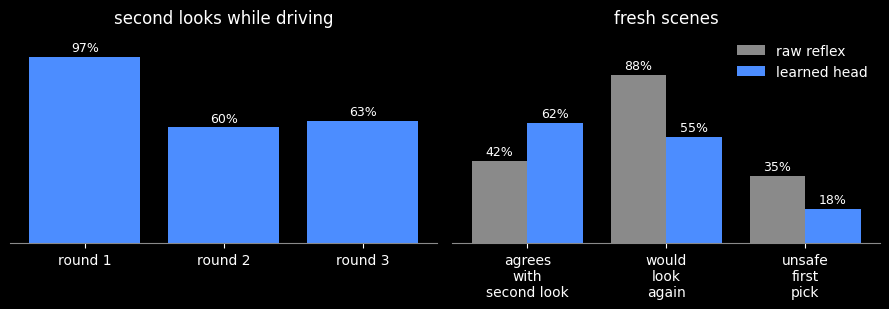

In [9]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
if plt:
    blue, grey = "#4c8dff", "#8a8a8a"
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2), facecolor="black")
    for ax in (a1, a2):
        ax.set_facecolor("black")
        ax.tick_params(colors="white")
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color(grey)
        ax.set_ylim(0, 1.1)
        ax.set_yticks([])
        ax.spines["left"].set_visible(False)
    pct = dict(color="white", padding=2, fontsize=9, fmt=lambda v: f"{v:.0%}")
    a1.bar_label(a1.bar([f"round {h['round']}" for h in history], [h["second_look_rate"] for h in history], color=blue), **pct)
    a1.set_title("second looks while driving", color="white")
    metrics = list(results["learned head"])
    xs = range(len(metrics))
    a2.bar_label(a2.bar([i - 0.2 for i in xs], [results["raw Zoro-1 reflex"][m] for m in metrics], 0.4, color=grey,
                        label="raw reflex"), **pct)
    a2.bar_label(a2.bar([i + 0.2 for i in xs], [results["learned head"][m] for m in metrics], 0.4, color=blue,
                        label="learned head"), **pct)
    a2.set_xticks(list(xs), [m.replace(" ", "\n", 2) for m in metrics])
    a2.set_title("fresh scenes", color="white")
    a2.legend(frameon=False, labelcolor="white")
    plt.tight_layout()
    plt.show()

## Checks

These fail loudly if the demo breaks (they run in mock mode too). The last one only holds in mock mode, where the
fake reflex is built to ignore the passenger; with the real model, read the table above.

In [10]:
assert len(history) == ROUNDS and len(X) == len(y) > 0
assert all(0 <= v <= 1 for r in results.values() for v in r.values())
assert all(rollout(scene, label)["safe"] or not any(rollout(scene, m)["safe"] for m in MOVES) for scene, _, label in test)
if MOCK:
    assert results["learned head"]["agrees with second look"] > results["raw Zoro-1 reflex"]["agrees with second look"]
print("all checks passed")

all checks passed
